In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

# Basic cleaning for visualization
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df['Survived_Label'] = df['Survived'].map({0: 'Did not survive', 1: 'Survived'})
df['Class'] = df['Pclass'].map({1: '1st', 2: '2nd', 3: '3rd'})

# Consistent style for all charts
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 100

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Survived_Label,Class
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Did not survive,3rd
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Survived,1st
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Survived,3rd
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Survived,1st
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Did not survive,3rd


# Titanic Dataset: Data Visualization
**Author:** ATHAMBAWA FATHIMA ANEESIYA | **Internship:** CodeAlpha Data Analytics

## 1. Objective
To transform the Titanic passenger data into clear visuals that reveal who survived and why.

## 2. Dataset
891 passengers and 12 variables. Source: https://github.com/datasciencedojo/datasets

## 3. Visualizations
### Chart 1: Overall Survival

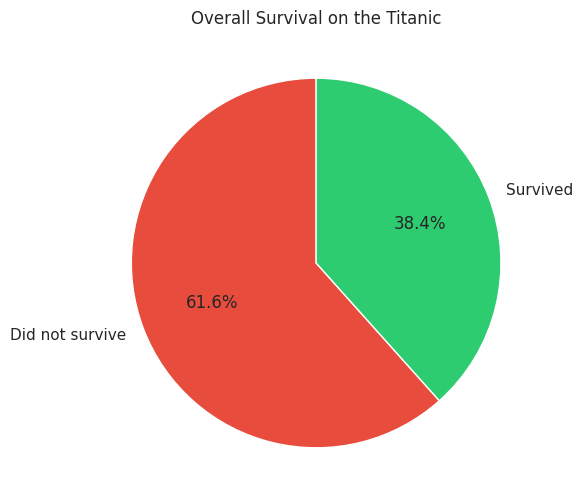

In [2]:
plt.figure(figsize=(6, 6))
counts = df['Survived_Label'].value_counts()
plt.pie(counts, labels=counts.index, autopct='%1.1f%%',
        startangle=90, colors=['#e74c3c', '#2ecc71'])
plt.title('Overall Survival on the Titanic')
plt.show()

### Chart 2: Survival Rate by Passenger Class and Gender
Women in every class survived at higher rates than men.

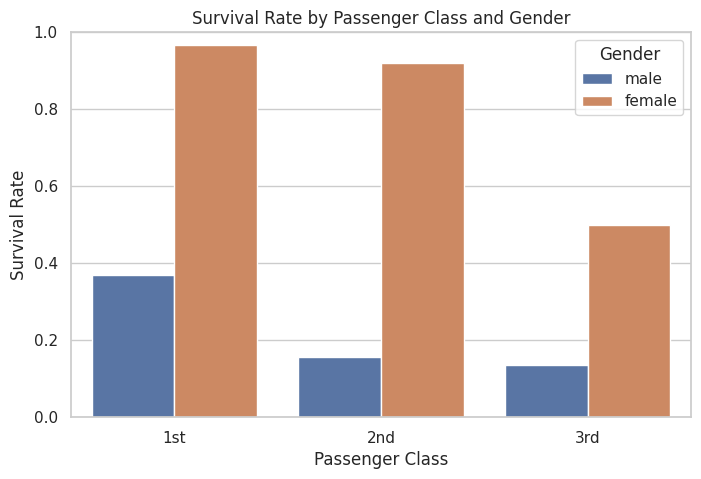

In [3]:
plt.figure(figsize=(8, 5))
sns.barplot(x='Class', y='Survived', hue='Sex', data=df,
            order=['1st', '2nd', '3rd'], errorbar=None)
plt.title('Survival Rate by Passenger Class and Gender')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.ylim(0, 1)
plt.legend(title='Gender')
plt.show()


### Chart 3: Age Distribution by Survival Status
Young children had better survival odds than other age groups.

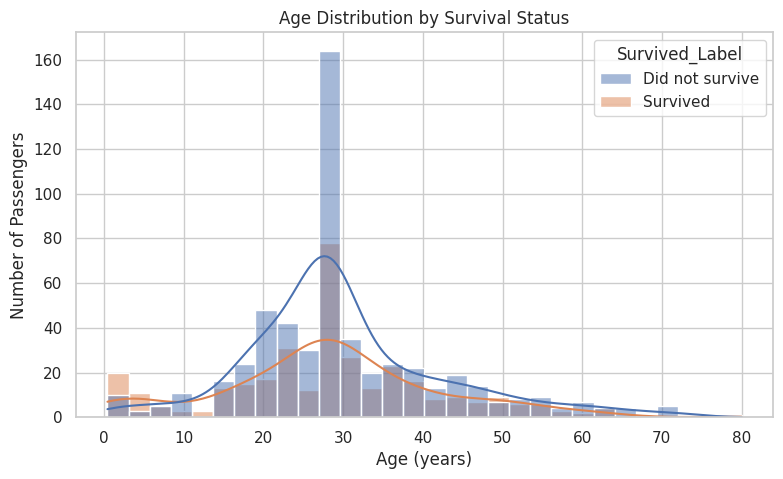

In [4]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x='Age', hue='Survived_Label', bins=30,
             kde=True, multiple='layer', alpha=0.5)
plt.title('Age Distribution by Survival Status')
plt.xlabel('Age (years)')
plt.ylabel('Number of Passengers')
plt.show()

### Chart 4: Ticket Fare by Passenger Class
First class paid the highest fares, with several extreme outliers.

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Class', y='Fare', data=df, order=['1st', '2nd', '3rd'])
plt.title('Ticket Fare by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Fare')
plt.show()

### Chart 5: Survival Rate by Port of Embarkation
Passengers who boarded at Cherbourg (C) had the highest survival rate.

In [ ]:
plt.figure(figsize=(7, 5))
sns.barplot(x='Embarked', y='Survived', data=df,
            order=['C', 'Q', 'S'], errorbar=None)
plt.title('Survival Rate by Port of Embarkation')
plt.xlabel('Port (C = Cherbourg, Q = Queenstown, S = Southampton)')
plt.ylabel('Survival Rate')
plt.ylim(0, 1)
plt.show()

## 4. Summary Dashboard
The four key views are combined into one dashboard.

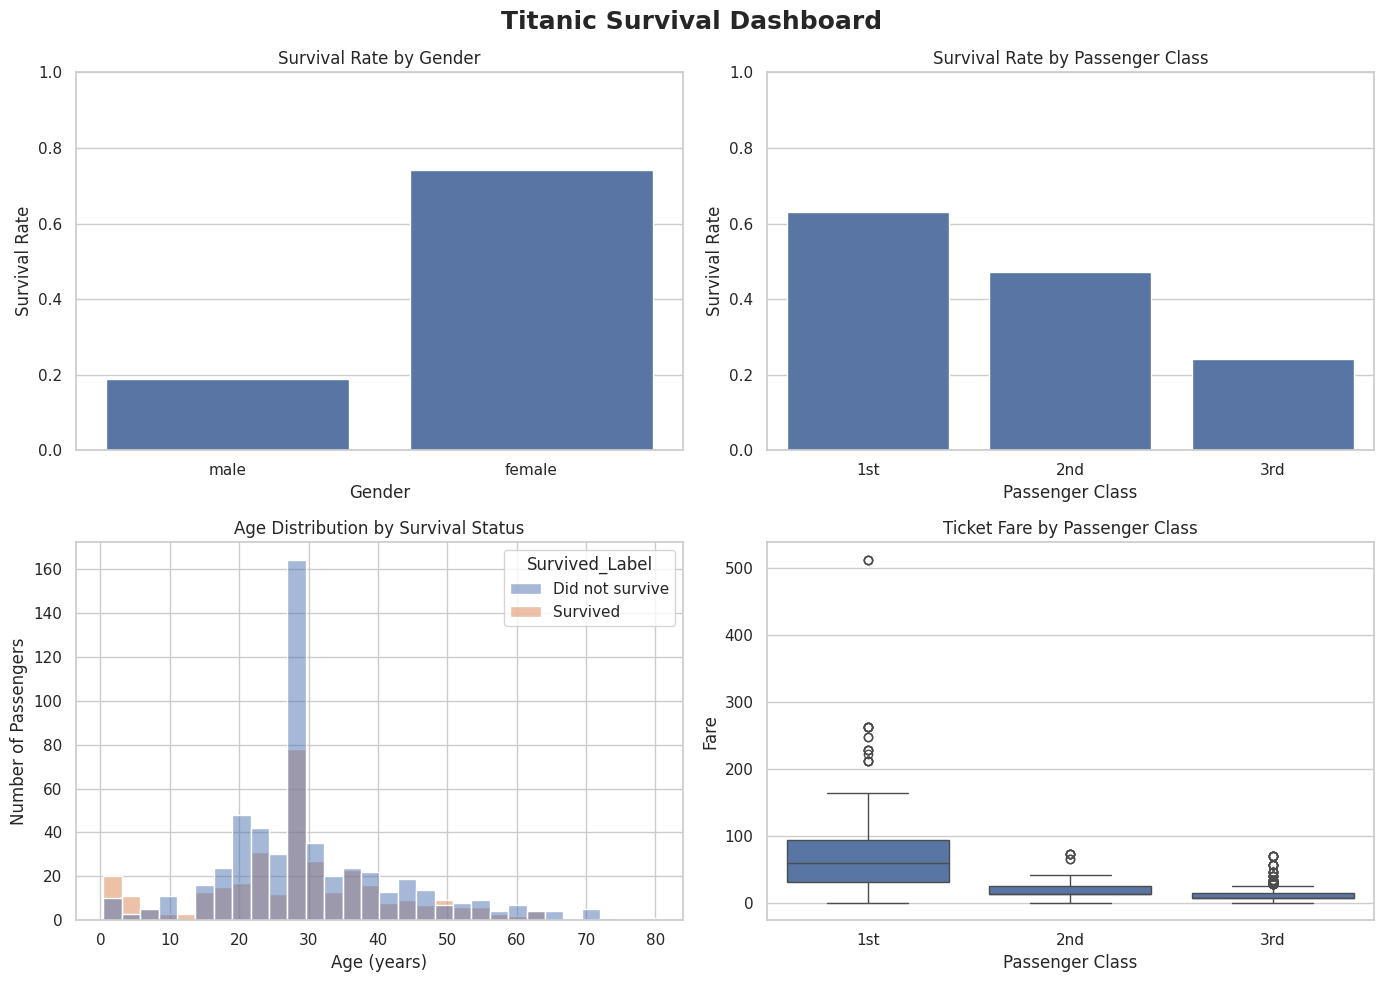

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Titanic Survival Dashboard', fontsize=18, fontweight='bold')

# Top left: survival by gender
sns.barplot(x='Sex', y='Survived', data=df, ax=axes[0, 0], errorbar=None)
axes[0, 0].set_title('Survival Rate by Gender')
axes[0, 0].set_xlabel('Gender')
axes[0, 0].set_ylabel('Survival Rate')
axes[0, 0].set_ylim(0, 1)

# Top right: survival by class
sns.barplot(x='Class', y='Survived', data=df, order=['1st', '2nd', '3rd'],
            ax=axes[0, 1], errorbar=None)
axes[0, 1].set_title('Survival Rate by Passenger Class')
axes[0, 1].set_xlabel('Passenger Class')
axes[0, 1].set_ylabel('Survival Rate')
axes[0, 1].set_ylim(0, 1)

# Bottom left: age distribution
sns.histplot(data=df, x='Age', hue='Survived_Label', bins=30,
             ax=axes[1, 0], multiple='layer', alpha=0.5)
axes[1, 0].set_title('Age Distribution by Survival Status')
axes[1, 0].set_xlabel('Age (years)')
axes[1, 0].set_ylabel('Number of Passengers')

# Bottom right: fare by class
sns.boxplot(x='Class', y='Fare', data=df, order=['1st', '2nd', '3rd'],
            ax=axes[1, 1])
axes[1, 1].set_title('Ticket Fare by Passenger Class')
axes[1, 1].set_xlabel('Passenger Class')
axes[1, 1].set_ylabel('Fare')

plt.tight_layout()
plt.show()

## 5. Key Insights and Conclusion

**Insights:**
- **Overall:** About 38% of passengers survived.
- **Gender:** Women survived at about 74%, compared with about 19% for men. This held true in every passenger class.
- **Class:** Survival declined with class: about 63% (1st), 47% (2nd), and 24% (3rd).
- **Age:** Children had the highest survival rate, at about 58%.
- **Fare:** First-class fares were much higher and showed extreme outliers.
- **Port:** Passengers from Cherbourg had the highest survival rate.

**Conclusion:**
Survival on the Titanic was strongly linked to gender, passenger class, and age. Women, children, and first-class passengers had the best chances of survival. The visuals show that social status and the "women and children first" policy shaped who survived.